# Module 00 — Foundation data layer

**Thesis:** *Cartographie des mutations de l'emploi dans l'industrie automobile européenne (2006–2025)* — CIRED / SPECULAR

This notebook builds and **validates** the data substrate that every later module sits on. It computes no results; it makes sure the inputs are trustworthy and that their limits are explicit.

### The three rules encoded in `foundation.py`

1. **France always uses URSSAF.** Eurostat regional data is unreliable for France. `eurostat_panel()` drops France by default so no figure ever mixes the two.
2. **NUTS vintages are reconciled from the data, not assumed.** The 2008–2020 extract carries *both* legacy and current codes for recoded regions (Saxony `DED1/DED3` → `DED4/DED5`; Brandenburg `DE41+DE42` → `DE40`; Portugal `PT17` → `PT1B`). We prefer rows that carry a value, then current codes over legacy ones.
3. **NACE 27 is read at two levels.** Eurostat only offers the C27 aggregate at NUTS-2, but that bundles batteries and motors with lighting, wiring and domestic appliances. URSSAF gives 4-digit APE for France, so we compute both — and the French comparison *bounds the bias* in the European aggregate.

### Coverage facts verified against the files
- The **UK** appears in the 2008–2020 extract only (absent from 2021+).
- **Turkey and Russia** are absent from both → those 4 plants have no Eurostat macro link.

In [2]:
# Reload edited .py modules automatically — without this, a kernel that
# imported an older version keeps serving it (AttributeError on new functions).
%load_ext autoreload
%autoreload 2

import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import foundation as fd

# ---- EDIT THESE TWO PATHS -------------------------------------------------
# --- archive bootstrap: resolve paths from the project root ---------------
# The original was CONFIG.data_dir = './data', which assumed the notebook ran
# beside a data/ folder. In the archived layout the inputs live in
# 02_data_inputs/, so the path is taken from specular_paths instead and this
# notebook works from wherever it is opened.
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # 01_code/
from specular_paths import P
fd.CONFIG.data_dir = str(P.inputs)
fd.CONFIG.out_dir  = str(P.outputs)
print('data:', fd.CONFIG.data_dir)
fd.CONFIG.out_dir  = './outputs'    # where tables / figures / maps are written
# ---------------------------------------------------------------------------

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
print('data_dir:', fd.CONFIG.data_dir)

data_dir: ./data


## 1. Required files

Check everything is present before building.

In [4]:
required = [
    fd.CONFIG.f_plants,
    fd.CONFIG.f_eurostat_c29_old, fd.CONFIG.f_eurostat_c29_new,
    fd.CONFIG.f_eurostat_c27_old, fd.CONFIG.f_eurostat_c27_new,
    fd.CONFIG.f_urssaf_c29, fd.CONFIG.f_urssaf_c27,
]
for f in required:
    p = fd.CONFIG.path(f)
    print(('OK   ' if p.exists() else 'MISS '), f)

OK    auto_plants_models_harmonised.xlsx
OK    sbs_r_nuts06_r2__custom_21357611_spreadsheet.xlsx
OK    sbs_r_nuts2021__custom_21357526_spreadsheet.xlsx
OK    sbs_r_nuts06_r2__custom_21359815_spreadsheet.xlsx
OK    sbs_r_nuts2021__custom_21359779_spreadsheet.xlsx
OK    etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last.xlsx
OK    urssaf_nace_27.xlsx


## 2. Build everything

`build_all()` returns a dict of tidy DataFrames:

| key | contents |
|---|---|
| `plants` | plant registry (89 plants, 14 countries, 8 groups) |
| `employment` | plant × year headcount (two measurement bases — see below) |
| `production` | plant × year output |
| `model_year` / `model_year_sized` | plant × model × year, with ADEME size attributes joined |
| `eurostat_c29_emp` / `eurostat_c27_emp` | NUTS-2 panels, 2008–2023, France excluded |
| `urssaf_c29_*` / `urssaf_c27_*` | France, commune/département/national, two APE scopes |
| `crosswalk` | plant → NUTS-2 (both vintages) + coordinates |

In [6]:
d = fd.build_all()

Loading micro layer (plant panel) ...
Loading macro layer A (Eurostat SBS, NUTS-2) ...
Loading macro layer B (URSSAF, France) ...
Building plant -> NUTS-2 crosswalk ...
Done.


In [7]:
fd.print_validation_report(d)

FOUNDATION VALIDATION REPORT

[1] PLANT PANEL
    plants ................ 89
    countries ............. 14  (BE, CZ, DE, ES, FR, GB, HU, IT, PL, PT, RO, RU, SK, TR)
    groups ................ 8
    classifications ....... {'assembly': 59, 'component': 26, 'historic': 2, 'rnd': 1, 'logistics': 1}

[2] EMPLOYMENT (micro)
    plant-year rows ....... 988
    plants with data ...... 76
    measurement bases ..... {'plant_reported': 568, 'commune_all_APE': 420}
    status ................ {'reference_year_unknown': 420, 'observed': 333, 'carried_forward': 215, 'back_filled_from_later_year': 20}
    NOTE: plant_reported and commune_all_APE (FR) are different
          quantities and must not be pooled without a caveat.

[2b] IMPUTED EMPLOYMENT PANEL (Amelia, M=50)
    plants x years ........ 35 x 20 = 700 cells (balanced grid)
    status ................ {'observed': 317, 'imputed_internal': 203, 'imputed_edge': 105, 'inactive': 75}
    observed / active ..... 317/625 (51%)  -> 49% imputed


## 3. The measurement-basis caveat

`employment` mixes two **different quantities**. They must never be pooled into a single European total without saying so:

* `plant_reported` — headcount for the plant itself (DE, ES, GB, HU, …)
* `commune_all_APE` — URSSAF employment for the whole commune summed over auto APE codes (FR)

Use the boolean `is_plant_level` to filter.

In [9]:
emp = d['employment']
print(emp.groupby(['measurement_basis', 'country_iso2']).size().unstack(fill_value=0).to_string())
print()
print('observed vs derived:')
print(emp['employees_status'].value_counts().to_string())

country_iso2       BE  CZ   DE  ES   FR  GB  HU  IT  PL  PT  SK  TR
measurement_basis                                                  
commune_all_APE     0   0    0   0  420   0   0   0   0   0   0   0
plant_reported     28   5  325  53   15  52  28   1  10   9   9  33

observed vs derived:
employees_status
reference_year_unknown         420
observed                       333
carried_forward                215
back_filled_from_later_year     20


## 3b. The imputed employment panel (Amelia, M=50)

`employment_completed_summary.csv` is a **balanced 35 × 20 grid** (2006–2025) for the German-block scrape universe, minus five plants too data-poor to impute (Eisenach, Wackersdorf, Porsche Leipzig, Osnabrück, Września).

| status | meaning | in aggregates? |
|---|---|---|
| `observed` | a real scraped/verified value | yes |
| `imputed_internal` | gap bracketed by observations | yes, with uncertainty |
| `imputed_edge` | start/end of window, nothing to bracket it | yes, but least certain |
| `inactive` | plant did not exist / had closed | **no — NaN, never zero** |

`est_sd_log` is the Rubin-pooled SD on the **log** scale: ≈0.10 ≈ a ±10% one-sigma band.

### ⚠️ The asymmetry to respect
Only these 35 plants have a complete series. Every other plant keeps its patchy observed record, so a naive sum over *all* plants mixes a complete panel with an incomplete one and shows **spurious growth as coverage improves**. Use `in_imputed_universe` for trends and aggregates.

In [11]:
imp = d['employment_imputed']
ep  = d['employment_panel']

print('balanced grid :', imp['plant_uid'].nunique(), 'plants x', imp['year'].nunique(), 'years =', len(imp), 'cells')
print('status        :', imp['status'].value_counts().to_dict())
print()
print('analysis-ready series (employment_panel):')
print(ep['value_kind'].value_counts().to_string())

balanced grid : 35 plants x 20 years = 700 cells
status        : {'observed': 317, 'imputed_internal': 203, 'imputed_edge': 105, 'inactive': 75}

analysis-ready series (employment_panel):
value_kind
urssaf_commune      420
observed            317
imputed_internal    203
observed_scraped    131
imputed_edge        105
derived_scraped      90


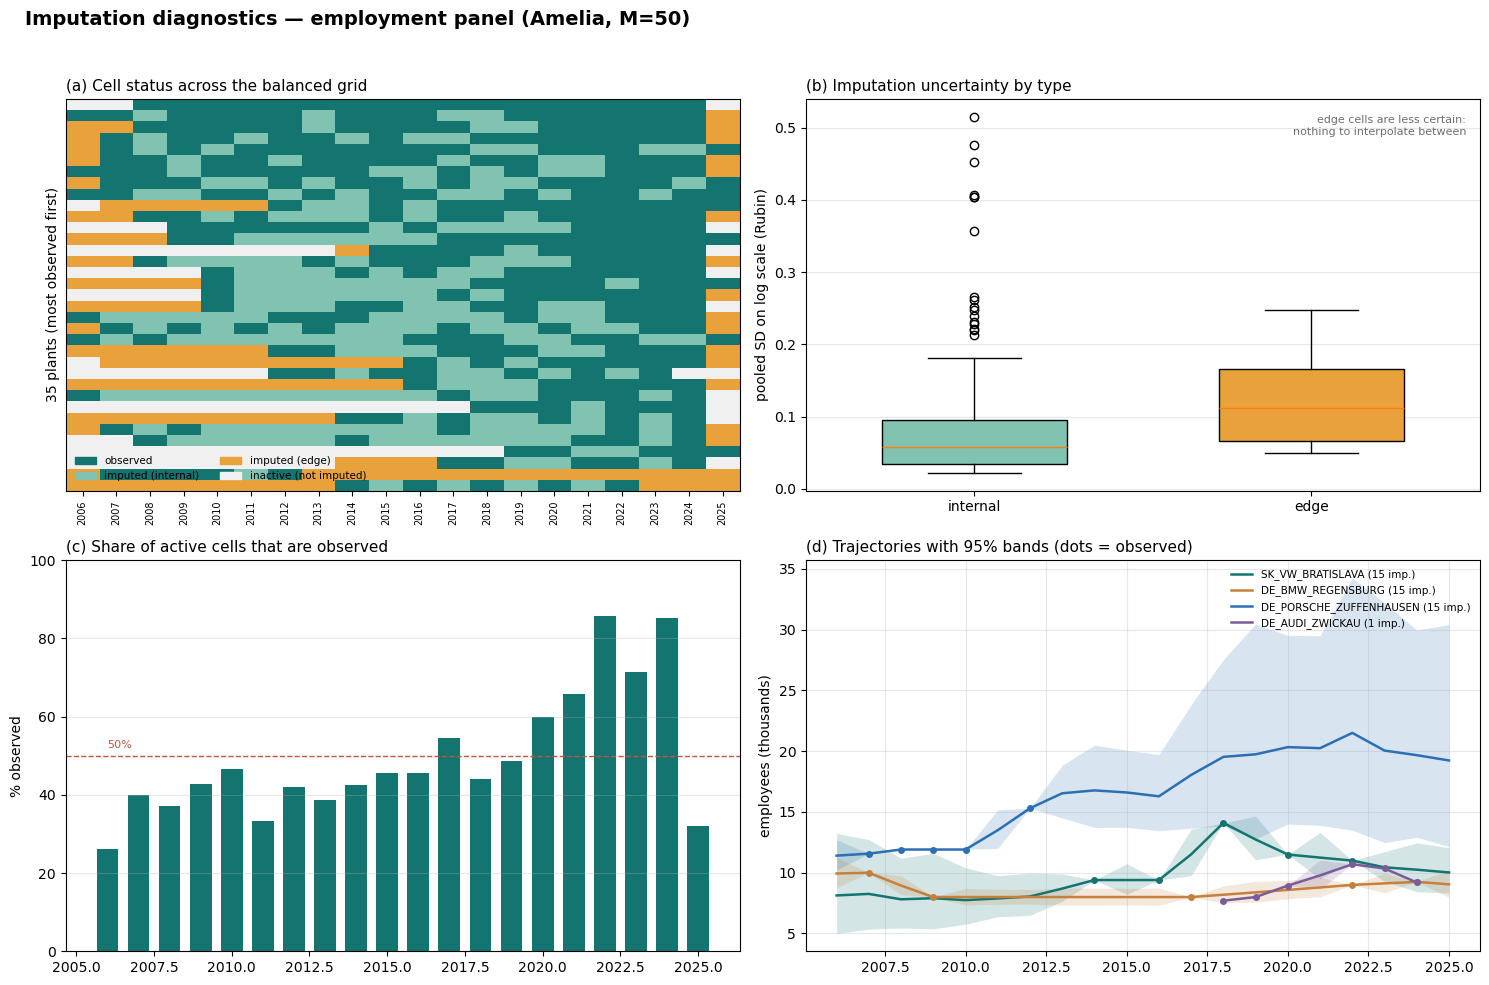

In [12]:
fig = fd.plot_imputation_diagnostics(d, save=f'{fd.CONFIG.out_dir}/fig00_imputation.png')
plt.show()

### 3c. Why the endpoints of any trend are the weakest claim

Panel (c) above is the one to remember when writing results: the share of **active cells that are observed** is only ~26% in 2006 and ~32% in 2025, against ~85% in 2022–2024.

So a headline of the form *“employment changed X% between 2006 and 2025”* rests on the two **least evidenced** years. Options to settle with the supervisors:
* report change over a better-observed window (e.g. 2012–2024),
* report the endpoints **with their imputation intervals**, or
* report both and show the sensitivity.

In [14]:
# Balanced panel vs naive all-plants sum — why the universe matters.
bal   = ep[ep['in_imputed_universe']].groupby('year')['employees'].sum() / 1000
naive = ep[ep['is_plant_level']].groupby('year')['employees'].sum() / 1000
obs_share = (imp[~imp['is_inactive']].groupby('year')['status']
             .apply(lambda s: (s == 'observed').mean() * 100).round(0))

cmp = pd.DataFrame({'balanced_35_plants_k': bal.round(0),
                    'naive_all_plant_level_k': naive.round(0),
                    'pct_observed_in_panel': obs_share})
display(cmp)
print('The naive column drifts upward partly because coverage improves — not a real trend.')

,balanced_35_plants_k,naive_all_plant_level_k,pct_observed_in_panel
year,,,
2006,257.0,265.0,26.0
2007,270.0,282.0,40.0
2008,270.0,295.0,37.0
2009,268.0,302.0,43.0
2010,283.0,317.0,47.0
2011,286.0,331.0,33.0
2012,300.0,353.0,42.0
2013,310.0,373.0,39.0
2014,333.0,389.0,42.0


The naive column drifts upward partly because coverage improves — not a real trend.


## 3d. Stale and post-closure values ⚠️

The source panel carries values forward past the point where they are known — and in some cases past the point the plant existed. `foundation` now flags this centrally, so every module inherits it.

| flag | meaning |
|---|---|
| `is_post_closure` | year is after a **documented** closure (`KNOWN_CLOSURES`) |
| `is_frozen_series` | ≥5 consecutive **identical** non-observed values — carried forward so long it has stopped being evidence |
| `is_suspect` | either of the above |

Found in the current data:

| plant | value | years | note |
|---|---|---|---|
| Ford Genk | 4,300 | 2015–2025 | **closed Dec 2014** |
| Ford Bridgend | 1,980 | 2012–2025 | **closed 2020** |
| Toyota Onnaing | 3,732 | 2011–2025 | 15 years frozen; plant still operating |
| Ford Saarlouis | 6,800 | 2016–2025 | wound down |
| BMW Regensburg · Mercedes Düsseldorf · Ford Otosan | — | ~5–7 yrs | frozen runs |

A frozen series is not necessarily *wrong* — a stable plant may genuinely hold headcount — but it carries **no information about change**, so any growth rate computed across it is an artefact of the source.

> Values are **flagged, not deleted**. Pass `drop_post_closure=True` / `drop_frozen=True` to `employment_panel()` to exclude them.

In [ ]:
ep = d['employment_panel']
print('post-closure:', int(ep['is_post_closure'].sum()),
      '| frozen:', int(ep['is_frozen_series'].sum()),
      '| suspect:', int(ep['is_suspect'].sum()), '/', len(ep))

display(ep[ep['is_suspect']].groupby(['plant_uid','plant_name']).agg(
    rows=('year','size'), first=('year','min'), last=('year','max'),
    value=('employees','first'), post_closure=('is_post_closure','any')))

clean = fd.employment_panel(drop_post_closure=True, drop_frozen=True)
print(f'\nrows with flags kept: {len(ep)}  ->  dropped: {len(clean)}')

## 4. Diagnostics — what the data can and cannot support

Four panels for the methods chapter:

**(a)** micro employment coverage by country × year — shows DE ramping from ~20% to ~95%, FR complete (URSSAF), others partial.  
**(b)** Eurostat missing vs *confidential* cells — suppression is not random: it concentrates in regions dominated by one or two large plants, i.e. exactly our regions of interest.  
**(c)** ADEME size-attribute coverage of the model mix — ~15% overall, but FR/ES ≈ 47% and DE ≈ 8%.  
**(d)** the France C27 demonstration — the aggregate falls while batteries rise.

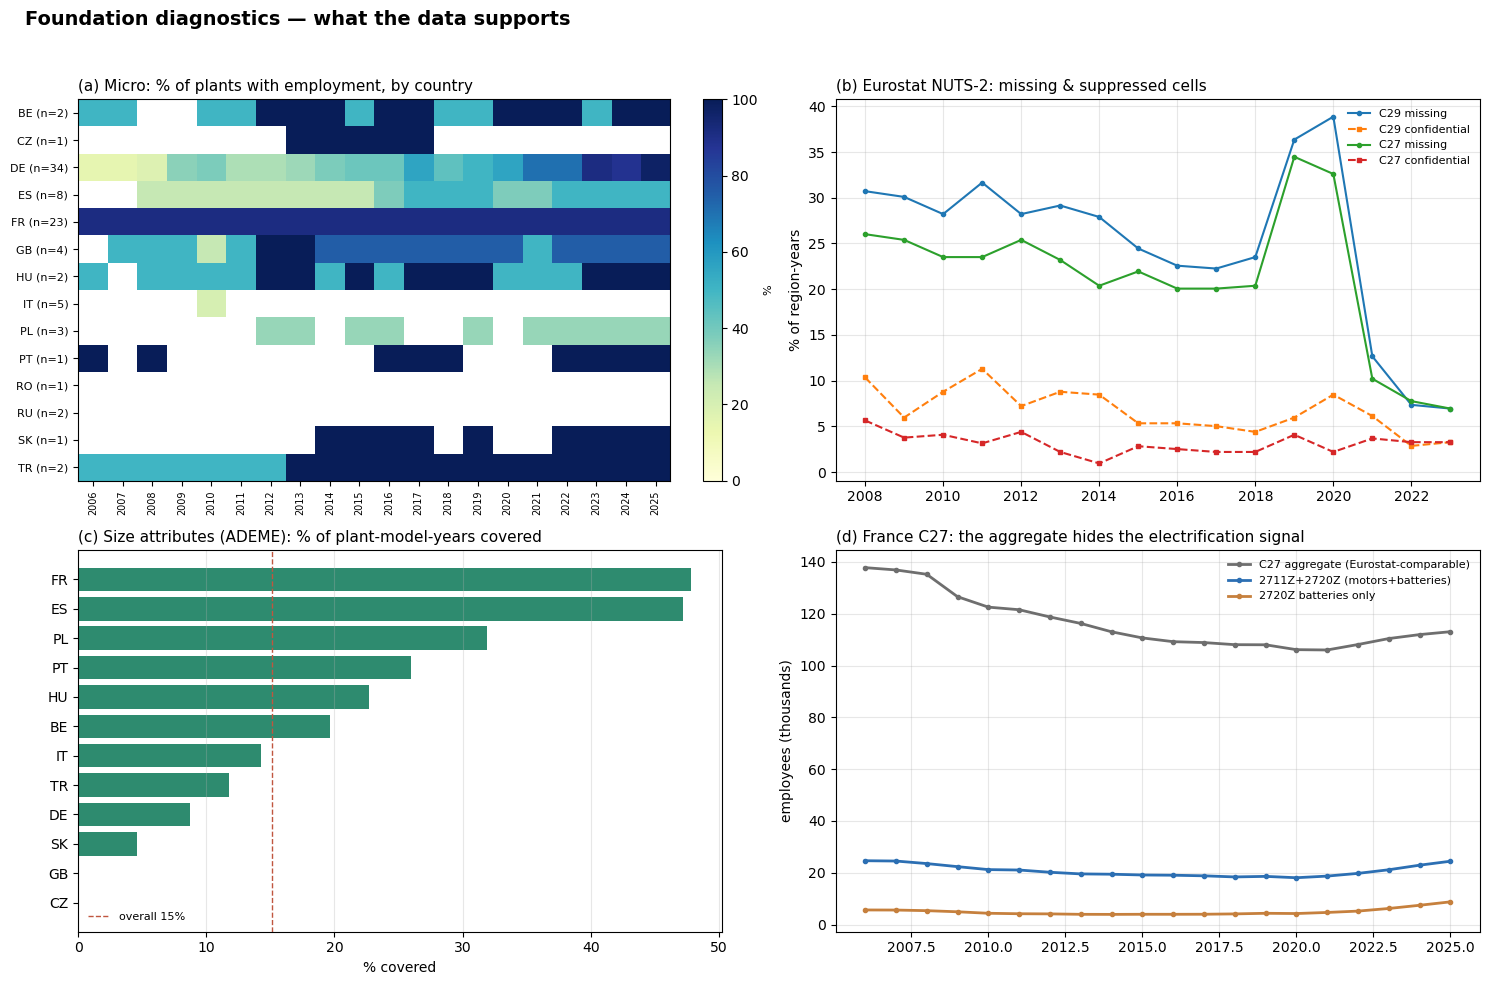

In [16]:
fig = fd.plot_coverage_diagnostics(d, save=f'{fd.CONFIG.out_dir}/fig00_diagnostics.png')
plt.show()

### 4b. The NUTS vintage seam

The two extracts meet between 2020 and 2021. This plots the spliced series for the regions that host our plants, with the seam marked, so any discontinuity created by the recoding is **visible** rather than assumed away.

> Watch the 2019–2020 years: missingness in the old extract peaks there (~39%), so apparent drops at the seam may be coverage, not real decline.

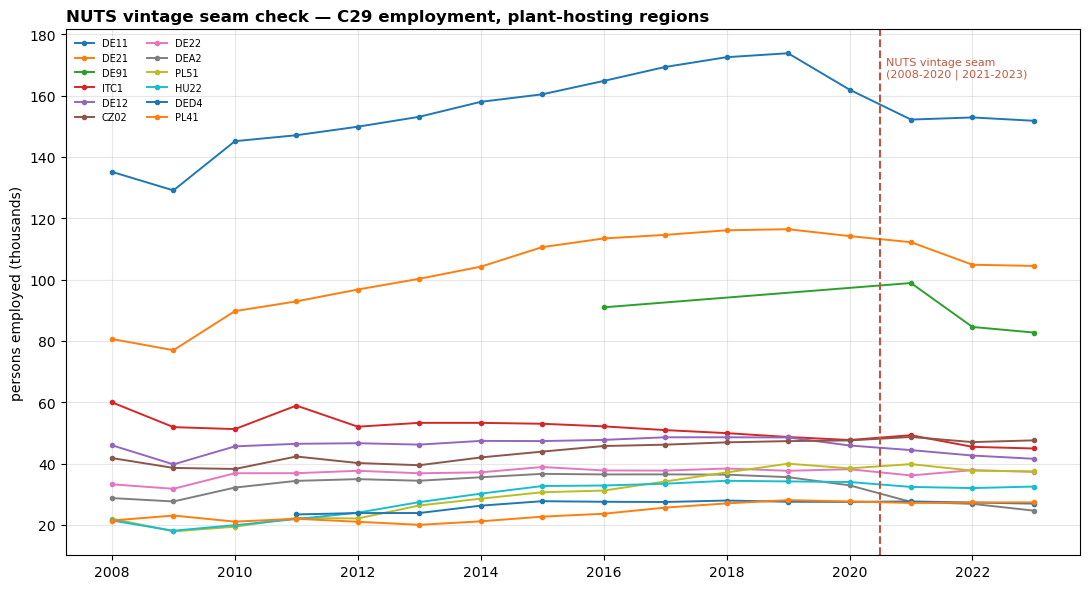

In [18]:
fig = fd.plot_nuts_seam_diagnostic(d, save=f'{fd.CONFIG.out_dir}/fig00_nuts_seam.png')
plt.show()

## 5. The France C27 two-level read (RULE 3)

This is the evidence that **bounds** the assumption we have to make for the rest of Europe. In France, where 4-digit APE is observable, the C27 aggregate moves *opposite* to the electrification signal.

In [20]:
comp = (d['urssaf_c27_nat_all'][['year','employees']].rename(columns={'employees':'C27_aggregate'})
        .merge(d['urssaf_c27_nat_narrow'][['year','employees']].rename(columns={'employees':'motors_batteries_2711_2720'}), on='year')
        .merge(d['urssaf_c27_nat_battery'][['year','employees']].rename(columns={'employees':'batteries_2720Z'}), on='year'))

base = comp[comp['year'] == 2006].iloc[0]
for c in ['C27_aggregate','motors_batteries_2711_2720','batteries_2720Z']:
    comp[c + '_idx100'] = 100 * comp[c] / base[c]

display(comp.set_index('year').round(0))
comp.to_csv(f'{fd.CONFIG.out_dir}/tbl00_france_c27_two_level.csv', index=False)

,C27_aggregate,motors_batteries_2711_2720,batteries_2720Z,C27_aggregate_idx100,motors_batteries_2711_2720_idx100,batteries_2720Z_idx100
year,,,,,,
2006,137787.0,24657.0,5654.0,100.0,100.0,100.0
2007,136901.0,24540.0,5622.0,99.0,100.0,99.0
2008,135228.0,23562.0,5384.0,98.0,96.0,95.0
2009,126574.0,22375.0,4952.0,92.0,91.0,88.0
2010,122546.0,21231.0,4376.0,89.0,86.0,77.0
2011,121543.0,21072.0,4194.0,88.0,85.0,74.0
2012,118743.0,20208.0,4139.0,86.0,82.0,73.0
2013,116253.0,19572.0,3972.0,84.0,79.0,70.0
2014,113027.0,19450.0,3946.0,82.0,79.0,70.0


## 6. Crosswalk review  ⚠️

**This table must be verified before publication.** Assignments are municipality-based; `validate_crosswalk()` confirms each code exists in the corresponding Eurostat extract, but it cannot confirm the *municipality → region* judgement itself.

`geo_confidence = medium` is used for the French plants, where the NUTS code is informational only (France uses URSSAF).

In [22]:
cw  = d['crosswalk']
val = d['crosswalk_validation']

print('plants without an Eurostat link (expected: RU x2, TR x2):')
display(cw.loc[~cw['has_eurostat_link'], ['plant_uid','city','country_iso2','geo_note']])

print('\nplants whose NUTS code differs between vintages:')
display(cw.loc[cw['nuts2_old'].notna() & cw['nuts2_new'].notna() & (cw['nuts2_old'] != cw['nuts2_new']),
               ['plant_uid','city','nuts2_old','nuts2_new','geo_note']])

cw.to_csv(f'{fd.CONFIG.out_dir}/crosswalk_FOR_REVIEW.csv', index=False)
val.to_csv(f'{fd.CONFIG.out_dir}/crosswalk_validation.csv', index=False)
print('\nwritten: crosswalk_FOR_REVIEW.csv')

plants without an Eurostat link (expected: RU x2, TR x2):


,plant_uid,city,country_iso2,geo_note
84,RU_FORD_VSEVOLOZHSK,Vsevolozhsk,RU,outside Eurostat
85,RU_TOYOTA_RUSSIA,Saint Petersburg,RU,outside Eurostat
87,TR_FORD_OTOSAN_KOCAELI,Kocaeli,TR,TR absent from both extracts
88,TR_TOYOTA_SAKARYA,Sakarya,TR,TR absent from both extracts



plants whose NUTS code differs between vintages:


,plant_uid,city,nuts2_old,nuts2_new,geo_note
19,DE_MERCEDES_LUDWIGSFELDE,Ludwigsfelde,DE42,DE40,Brandenburg recoded DE42->DE40
45,FR_INEOS_HAMBACH,Hambach,FR41,FRF3,URSSAF used
46,FR_RENAULT_BATILLY,Batilly,FR41,FRF3,URSSAF used
47,FR_RENAULT_CLEON,Cléon,FR23,FRD2,URSSAF used
48,FR_RENAULT_DIEPPE,Dieppe,FR23,FRD2,URSSAF used
49,FR_RENAULT_DOUAI,Douai,FR30,FRE1,URSSAF used
52,FR_RENAULT_LE_MANS,Le Mans,FR51,FRG0,URSSAF used
53,FR_RENAULT_MAUBEUGE,Maubeuge,FR30,FRE1,URSSAF used
54,FR_RENAULT_MEYZIEU,Meyzieu,FR71,FRK2,URSSAF used
55,FR_RENAULT_RUITZ,Ruitz,FR30,FRE1,URSSAF used



written: crosswalk_FOR_REVIEW.csv


### 6b. Visual check — interactive plant map (Folium)

The fastest way to catch a bad crosswalk row: if a marker lands in the wrong country or region, the assignment is wrong. Popups carry the NUTS assignment and the measurement basis.

In [24]:
m = fd.map_plants_folium(d['crosswalk'], d['employment'], year=2023,
                         save=f'{fd.CONFIG.out_dir}/map00_plants.html')
print('saved ->', os.path.abspath(f'{fd.CONFIG.out_dir}/map00_plants.html'))
print('If nothing renders below, the notebook is UNTRUSTED (Folium needs inline JS).')
print('Either trust the notebook, or just open that .html file in a browser.')
m

### 6c. Macro context — NUTS-2 choropleth (Plotly)

C29 employment by NUTS-2, using `regional_panel` = **Eurostat everywhere + URSSAF for France**. Using `eurostat_panel` alone leaves a France-shaped hole, because Rule 1 forbids Eurostat's French figures.

Hover shows the `source` for each region. Regions that are **missing or suppressed** stay blank by construction — never zero-filled.

> Geometries come from Eurostat GISCO and are cached in `out_dir`.

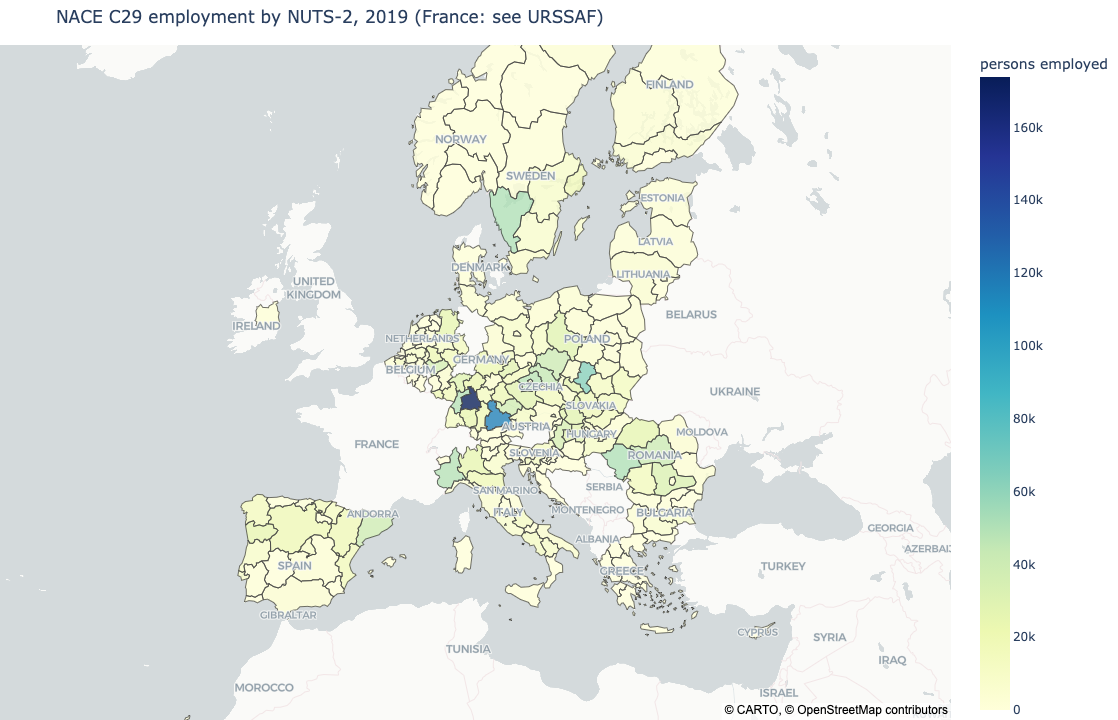

In [26]:
# regional_panel = Eurostat everywhere + URSSAF for France (Rule 1).
# eurostat_panel alone leaves a France-shaped hole in the map.
fig = fd.map_nuts_choropleth(d['regional_c29_nuts2'], 2019, level=2,
                             title='Automotive employment by region, 2019 '
                                   '(NUTS-2; France at departement level, URSSAF)',
                             save=f'{fd.CONFIG.out_dir}/map00_nuts_c29_2019.html')
fig.show()

## 7. Export

Write every tidy table to CSV so later modules can load them without re-parsing the Excel sources.

In [28]:
fd.export_all(d)

Wrote 22 tables to outputs


---
## What to check before we move to Module 01

1. **Crosswalk** — open `crosswalk_FOR_REVIEW.csv` and the Folium map; confirm the region assignments, especially the recoded ones (Ludwigsfelde `DE42→DE40`, Palmela `PT17→PT1B`, the Saxony plants).
2. **Analysis universe** — the imputed panel gives a clean balanced set of **35 plants**. Decide whether headline European figures use that balanced universe, or all plants with coverage reported alongside.
3. **Trend endpoints** — 2006 (~26% observed) and 2025 (~32%) are the weakest years. Choose the reporting window.
4. **Plant scope** — whether RU (2) and TR (2) plants stay (no Eurostat link), and whether `historic` / `rnd` / `logistics` sites belong in employment aggregates.
5. **Seam** — decide whether Eurostat results stop at 2020 or run to 2023 with a caveat.

**Next — Module 01: spatial structural change** (shift-share East↔West on Eurostat C29, location quotients, concentration), framed through Pavlínek's integrated peripheries and Lefèvre's structural-change lens.